# Hunga Tonga–Hunga Ha'apai: land and vegetation area over time

Part 2 of the Optical Detectors assignment. The notebook

1. measures the land area of the island from the Google Earth (white-light) JPGs with an HSV colour mask,
2. measures the vegetated area from the Sentinel-2 L2A images with an NDVI mask,
3. compares our spectral index with the one from the Sentinel-2 pipeline, and our land areas with an independent Sentinel-2 estimate.

All paths are relative to the repository root. Results are written to `sentinel-processed/`.

# Setting up the imported packages

In [1]:
import csv
import pathlib
import warnings
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import rgb_to_hsv
from scipy import ndimage
import rasterio
from rasterio.errors import NotGeoreferencedWarning
from rasterio.plot import reshape_as_image

# Define all relevant functions

In [2]:
EARTH_RADIUS_M = 6_371_000   # mean Earth radius


def read_image(path):
    """
    Read a JPG (or any raster) into an array with rasterio.

    Parameters
    ----------
    path : pathlib.Path
        Image file.

    Returns
    -------
    numpy.ndarray
        Image with shape (bands, rows, cols), e.g. (3, 1992, 2382) for the Google Earth JPGs.
    """
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', NotGeoreferencedWarning)   # the JPGs have no map coordinates
        with rasterio.open(path) as src:
            return src.read()                                    # shape (bands, rows, cols)


def scale_bar_length(rgb, threshold=200, rows=40, x_start=1900):
    """
    Measure the length of the Google Earth scale bar in pixels.

    The bar is the longest run of bright pixels in the bottom-right corner of the image.

    Parameters
    ----------
    rgb : numpy.ndarray
        Image with shape (3, rows, cols).
    threshold : float
        Grey level (0-255) above which a pixel counts as part of the bar.
    rows : int
        Number of rows at the bottom of the image to search.
    x_start : int
        First column of the search region.

    Returns
    -------
    length : int
        Bar length in pixels.
    (x0, x1, y) : tuple of int
        End columns and row of the bar in full-image coordinates (for plotting).
    """
    gray = rgb.mean(axis=0)
    corner = gray[-rows:, x_start:]
    bright = corner > threshold
    row = np.argmax(bright.sum(axis=1))           # the row with the most bright pixels
    cols = np.where(bright[row])[0]

    x0 = x_start + cols.min()                     # convert back to full-image coordinates
    x1 = x_start + cols.max()
    y = gray.shape[0] - rows + row
    return x1 - x0 + 1, (x0, x1, y)


def metres_per_pixel(bar_px, bar_m):
    """
    Pixel size of a JPG from its scale bar.

    Parameters
    ----------
    bar_px : int
        Scale bar length in pixels.
    bar_m : float
        Scale bar length in metres (the label under the bar).

    Returns
    -------
    float
        Metres per pixel (the same in x and y).
    """
    return bar_m / bar_px


def jpg_date(path):
    """Date of a Google Earth image from its name, e.g. '2014Feb.jpg' -> 2014-02-01."""
    return datetime.strptime(pathlib.Path(path).stem, '%Y%b')


def s2_date(folder):
    """Date of a Sentinel-2 folder from its name, e.g. 'S2_2017-07-12' -> 2017-07-12."""
    return datetime.strptime(pathlib.Path(folder).name[3:], '%Y-%m-%d')


def read_band(folder, name):
    """
    Read one Sentinel-2 product from a date folder.

    Parameters
    ----------
    folder : pathlib.Path
        Date folder, e.g. sentinel-data/S2_2017-07-12.
    name : str
        Product name between 'Sentinel-2_L2A_' and '.tiff', e.g. 'B04_Raw' or 'NDVI'.

    Returns
    -------
    data : numpy.ndarray
        float64 array, (rows, cols) for single bands or (bands, rows, cols) for colour products.
    meta : dict
        'res' (degrees per pixel in x and y), 'bounds' (degrees) and 'profile'
        (rasterio profile, used to write masks with the same georeferencing).
    """
    with rasterio.open(folder / f'Sentinel-2_L2A_{name}.tiff') as src:
        data = src.read().astype(np.float64)
        meta = {'res': src.res, 'bounds': src.bounds, 'profile': src.profile}
    return (data[0] if data.shape[0] == 1 else data), meta


def pixel_size_m(res, bounds):
    """
    Convert the angular pixel size of an EPSG:4326 image into metres.

    One degree of latitude is R * pi / 180 metres everywhere, while one degree of longitude
    shrinks by cos(latitude). The latitude used is the centre of the image.

    Parameters
    ----------
    res : tuple of float
        Pixel size (x, y) in degrees, from src.res.
    bounds : rasterio.coords.BoundingBox
        Image boundaries in degrees, from src.bounds.

    Returns
    -------
    dx, dy : float
        Pixel width (east-west) and height (north-south) in metres.
    """
    latitude = np.deg2rad((bounds.top + bounds.bottom) / 2)
    dx = EARTH_RADIUS_M * np.deg2rad(res[0]) * np.cos(latitude)
    dy = EARTH_RADIUS_M * np.deg2rad(res[1])
    return dx, dy


def pixel_area_m2(res, bounds):
    """Area of one Sentinel-2 pixel in m² (see pixel_size_m)."""
    dx, dy = pixel_size_m(res, bounds)
    return dx * dy


def normalized_difference(a, b):
    """
    Normalised difference index (a - b) / (a + b), e.g. NDVI = (B08 - B04) / (B08 + B04).

    Parameters
    ----------
    a, b : numpy.ndarray
        Reflectance bands with the same shape.

    Returns
    -------
    numpy.ndarray
        Index between -1 and 1, NaN where a + b = 0 (e.g. no-data pixels).
    """
    a = a.astype(np.float64)
    b = b.astype(np.float64)
    total = a + b
    with np.errstate(invalid='ignore', divide='ignore'):
        index = (a - b) / total
    index[total == 0] = np.nan
    return index


def area_from_mask(mask, pixel_area):
    """
    Area covered by a boolean mask.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        True for the pixels to count.
    pixel_area : float
        Area of one pixel in m².

    Returns
    -------
    float
        Area in m².
    """
    return np.count_nonzero(mask) * pixel_area


def save_mask(mask, path, profile=None):
    """
    Save a boolean mask as 0/1.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        Mask to save.
    path : pathlib.Path
        Output file. Use '.tif' together with `profile`, '.png' otherwise.
    profile : dict, optional
        rasterio profile of the source image. If given, the mask is written as a GeoTIFF with
        the same georeferencing; if not (the JPGs), it is written as a PNG.
    """
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if profile is None:
        plt.imsave(path, mask.astype(np.uint8), cmap='gray', vmin=0, vmax=1)
        return
    profile = {key: value for key, value in profile.items() if key != 'photometric'}
    profile.update(driver='GTiff', count=1, dtype='uint8', nodata=None)
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(mask.astype(np.uint8), 1)


def land_mask_hsv(rgb, h_range, s_range, v_range, crop_bottom=60):
    """
    Separate land from sea in a Google Earth image using HSV thresholds.

    Parameters
    ----------
    rgb : numpy.ndarray
        Image with shape (3, rows, cols), values 0-255.
    h_range, s_range, v_range : tuple of float
        (min, max) of hue, saturation and value (all 0-1) that count as land.
    crop_bottom : int
        Rows at the bottom of the image to ignore (Google Earth logo and scale bar).

    Returns
    -------
    numpy.ndarray of bool
        True for land pixels, shape (rows, cols).
    """
    # TODO:
    #  - hsv = rgb_to_hsv(reshape_as_image(rgb) / 255)
    #  - select pixels inside the three ranges
    #  - set the bottom `crop_bottom` rows to False
    #  - think about white surf (low S, high V) and turquoise shallow water near the coast
    #  - optionally clean the mask: ndimage.binary_opening, ndimage.binary_fill_holes,
    #    or keep only the largest connected regions (ndimage.label)
    raise NotImplementedError


def vegetation_mask(ndvi, threshold):
    """
    Vegetation mask from an NDVI image.

    Parameters
    ----------
    ndvi : numpy.ndarray
        NDVI values (-1 to 1, NaN for no data).
    threshold : float
        Pixels with NDVI above this value count as vegetation.

    Returns
    -------
    numpy.ndarray of bool
        True for vegetation (NaN pixels are False).
    """
    # TODO
    raise NotImplementedError


def land_mask_ndwi(ndwi, threshold=0.0):
    """
    Land mask from NDWI = (B03 - B08) / (B03 + B08): water has NDWI > 0, land NDWI < 0.

    Parameters
    ----------
    ndwi : numpy.ndarray
        NDWI values (-1 to 1, NaN for no data).
    threshold : float
        Pixels with NDWI below this value count as land.

    Returns
    -------
    numpy.ndarray of bool
        True for land (NaN pixels are False).
    """
    # TODO
    raise NotImplementedError


def pipeline_vegetation_mask(ndvi_rgb):
    """
    Vegetation mask from the Sentinel-2 pipeline NDVI product.

    The pipeline file is a colour visualisation of NDVI (3 bands, 0-1), not the index itself,
    so vegetation has to be recovered from the colours.

    Parameters
    ----------
    ndvi_rgb : numpy.ndarray
        Pipeline NDVI image with shape (3, rows, cols).

    Returns
    -------
    numpy.ndarray of bool
        True where the pipeline colours correspond to vegetation.
    """
    # TODO: e.g. green-dominant pixels (G > R and G > B), or a hue range after rgb_to_hsv.
    #       Look at the colours of the image first (unique colours, a hue histogram).
    raise NotImplementedError


def compare_masks(mine, theirs):
    """
    Pixel-by-pixel comparison of two boolean masks with the same shape.

    Parameters
    ----------
    mine, theirs : numpy.ndarray of bool
        Our mask and the reference mask.

    Returns
    -------
    dict
        'agreement' (fraction of pixels where both masks agree), 'only_mine' and
        'only_theirs' (pixel counts where only one mask is True) and 'iou'
        (intersection over union of the True pixels).
    """
    # TODO
    raise NotImplementedError

# Code execution starts here.

## 0. Define the working directory and inputs
`EXCLUDE` lists the Google Earth images left out of the land-area analysis (see Section 3.4).

In [3]:
here = pathlib.Path('.')
jpg_dir = here / 'sentinel-data' / 'White_light'
s2_dir = here / 'sentinel-data'
out_dir = here / 'sentinel-processed'
out_dir.mkdir(exist_ok=True)

SCALE_BAR_M = 600          # every Google Earth scale bar is labelled 600 m
EXCLUDE = {'2021Dec'}      # eruption plume hides the island

jpg_files = sorted(jpg_dir.glob('*.jpg'), key=jpg_date)
s2_folders = sorted(s2_dir.glob('S2_*'), key=s2_date)

print("Google Earth:", [f.stem for f in jpg_files])
print("Sentinel-2:  ", [f.name for f in s2_folders])

Google Earth: ['2014Feb', '2016May', '2020Nov', '2021Dec', '2022Jan', '2023Oct']
Sentinel-2:   ['S2_2017-07-12', 'S2_2018-07-12', 'S2_2019-07-12']


## 1. Pixel-to-metre ratio of the Google Earth images
Each JPG has a scale bar in the bottom-right corner labelled 600 m. Its length in pixels gives the pixel size,
which is the same in x and y, so the area of one pixel is $(\mathrm{m/px})^2$.

### 1.1. Find the scale bar in one image

310 px from x = 2067 to 2376 at y = 1987


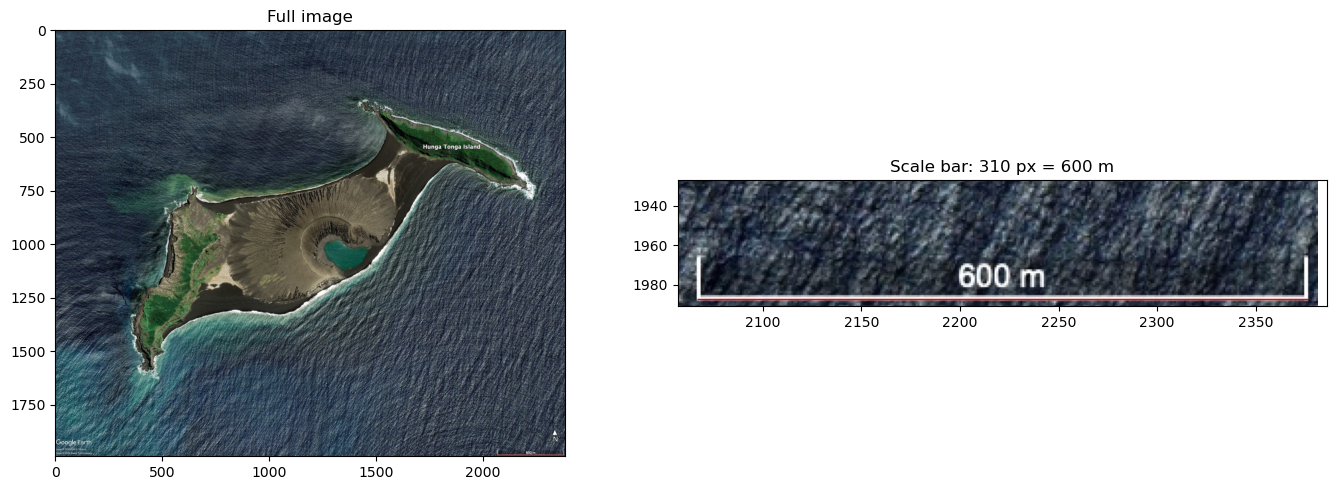

In [4]:
path = jpg_dir / '2020Nov.jpg'
rgb = read_image(path)
length, (x0, x1, y) = scale_bar_length(rgb)
print(f"{length} px from x = {x0} to {x1} at y = {y}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax in axes:
    ax.imshow(reshape_as_image(rgb))
    ax.plot([x0, x1], [y, y], color='red', lw=1)

axes[1].set_xlim(x0 - 10, x1 + 10)
axes[1].set_ylim(rgb.shape[1] - 1, y - 60)        # y increases downwards in image coordinates
axes[0].set_title('Full image')
axes[1].set_title(f'Scale bar: {length} px = {SCALE_BAR_M} m')

plt.tight_layout()
plt.show()

### 1.2. Pixel size of every image

In [5]:
jpg_scale = {}   # image name -> metres per pixel

for file in jpg_files:
    bar_px, _ = scale_bar_length(read_image(file))
    jpg_scale[file.stem] = metres_per_pixel(bar_px, SCALE_BAR_M)
    print(f"{file.stem:8} bar {bar_px:4d} px -> {jpg_scale[file.stem]:.3f} m/px, "
          f"{jpg_scale[file.stem] ** 2:.3f} m² per pixel")

2014Feb  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2016May  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2020Nov  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2021Dec  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2022Jan  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2023Oct  bar  310 px -> 1.935 m/px, 3.746 m² per pixel


TODO: comment on the result (are all bars the same length? how precise is the measurement, e.g. ±1 px on the bar → ±? % on the area?).

## 2. Pixel-to-metre ratio of the Sentinel-2 images
The Sentinel-2 products are in EPSG:4326, so `src.res` gives the pixel size in degrees. With the latitude $\phi$ at the centre of the image (from `src.bounds`)
and $R_\oplus$ the Earth's radius,

$$\Delta y = R_\oplus\,\Delta\phi, \qquad \Delta x = R_\oplus \cos\phi\,\Delta\lambda,$$

with $\Delta\phi$ and $\Delta\lambda$ in radians. The images are resampled to a nominal 10 m.

In [6]:
s2_pixel_area = {}   # folder name -> m² per pixel

for folder in s2_folders:
    _, meta = read_band(folder, 'B04_Raw')
    dx, dy = pixel_size_m(meta['res'], meta['bounds'])
    s2_pixel_area[folder.name] = dx * dy
    print(f"{folder.name}: res {meta['res'][0]:.3e}° x {meta['res'][1]:.3e}° -> "
          f"{dx:.2f} m x {dy:.2f} m = {dx * dy:.1f} m²")

S2_2017-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
S2_2018-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
S2_2019-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²


TODO: comment on the result: compare with the nominal 10 m, and say whether the variation of latitude across the image matters.

## 3. Land area from the Google Earth images (HSV mask)
In HSV space, sea and land separate mainly by hue (blue water vs brown/green land) and by saturation/value.
The thresholds are chosen on one image and then applied to all of them.

### 3.1. Explore the HSV values of one image

In [7]:
rgb = read_image(jpg_dir / '2020Nov.jpg')
hsv = rgb_to_hsv(reshape_as_image(rgb) / 255)   # shape (rows, cols, 3), values 0-1

# TODO: plot the H, S and V channels and/or their histograms to choose the land ranges

TODO: explain the chosen ranges.

### 3.2. Apply the mask to one image

In [8]:
# TODO: land = land_mask_hsv(rgb, h_range=(...), s_range=(...), v_range=(...))
#       plot the image and the mask side by side (or the mask contour on the image)

### 3.3. Land area of every image

In [9]:
land_area = {}   # image name -> land area in m²

for file in jpg_files:
    if file.stem in EXCLUDE:
        continue
    rgb = read_image(file)
    # TODO: land = land_mask_hsv(rgb, ...)
    # TODO: land_area[file.stem] = area_from_mask(land, jpg_scale[file.stem] ** 2)
    # TODO: save_mask(land, out_dir / f"{file.stem}_land_mask.png")

### 3.4. Excluding 2021Dec
TODO: explain why `2021Dec` is excluded (eruption plume covers the island), with the image as evidence.

In [10]:
# TODO: show 2021Dec.jpg

### 3.5. Land area over time

In [11]:
# TODO: plot land area (km²) against jpg_date(...), marking the eruption (15 January 2022)

TODO: discuss the evolution of the land area.

## 4. Vegetated area from Sentinel-2 (NDVI mask)
NDVI is computed from the bottom-of-atmosphere reflectance of the red (B04) and near-infrared (B08) bands:

$$\mathrm{NDVI} = \frac{B08 - B04}{B08 + B04}.$$

Vegetation reflects strongly in the NIR and absorbs red light, so it has high NDVI. Water is negative and bare rock/ash is close to 0.
The three Sentinel-2 dates (July 2017, 2018 and 2019) are all before the eruption.

### 4.1. NDVI of one date

In [12]:
folder = s2_folders[0]
red, meta = read_band(folder, 'B04_Raw')
nir, _ = read_band(folder, 'B08_Raw')
ndvi = normalized_difference(nir, red)

# TODO: plot ndvi (e.g. cmap='RdYlGn', vmin=-1, vmax=1) next to the True_color product, and its histogram

### 4.2. Choosing the NDVI threshold
TODO: justify the threshold (literature values, the histogram, the true-colour image).

In [13]:
NDVI_THRESHOLD = None   # TODO

### 4.3. Vegetated area of every date

In [14]:
veg_area = {}   # folder name -> vegetated area in m²

for folder in s2_folders:
    red, meta = read_band(folder, 'B04_Raw')
    nir, _ = read_band(folder, 'B08_Raw')
    ndvi = normalized_difference(nir, red)
    # TODO: vegetation = vegetation_mask(ndvi, NDVI_THRESHOLD)
    # TODO: veg_area[folder.name] = area_from_mask(vegetation, s2_pixel_area[folder.name])
    # TODO: save_mask(vegetation, out_dir / f"{folder.name}_vegetation_mask.tif", meta['profile'])

### 4.4. Vegetated area over time

In [15]:
# TODO: plot vegetated area (km²) against s2_date(...)

TODO: discuss the evolution of the vegetated area.

# Compare and Contrast

## 5. Comparison with the Sentinel-2 pipeline and between data sets
### 5.1. Our NDVI vs the pipeline NDVI
The pipeline `NDVI.tiff` is a 3-band colour visualisation (values 0–1) of the index, not the index itself.
The values cannot be compared directly, so we compare the vegetation masks pixel by pixel and the vegetated areas they give.

In [16]:
folder = s2_folders[0]
pipeline_rgb, _ = read_band(folder, 'NDVI')   # shape (3, rows, cols)

# TODO: show the pipeline image next to our NDVI

In [17]:
# TODO: for every date: mine = vegetation_mask(...), theirs = pipeline_vegetation_mask(...),
#       print compare_masks(mine, theirs) and both areas in a table

In [18]:
# TODO: map of where the masks disagree (only mine / only theirs) for one date

TODO: explain the differences quantitatively. Points to consider: the colour ramp quantises NDVI into steps,
the pipeline may use different thresholds/colour breaks, the raw band values are clipped to 0–1,
and pixels at the coast are mixed land/sea.

### 5.2. Sensitivity to the NDVI threshold

In [19]:
# TODO: vegetated area against threshold (e.g. np.linspace(0, 0.6, 61)) for each date,
#       with the chosen NDVI_THRESHOLD marked

TODO: how much does the vegetated area depend on the threshold?

### 5.3. Land area: Sentinel-2 vs Google Earth
An independent land-area estimate from Sentinel-2 uses NDWI = (B03 − B08) / (B03 + B08). Water has NDWI > 0.
These points are plotted together with the Google Earth series from Section 3.5.

In [20]:
s2_land_area = {}   # folder name -> land area in m²

for folder in s2_folders:
    green, meta = read_band(folder, 'B03_Raw')
    nir, _ = read_band(folder, 'B08_Raw')
    ndwi = normalized_difference(green, nir)
    # TODO: land = land_mask_ndwi(ndwi)
    # TODO: s2_land_area[folder.name] = area_from_mask(land, s2_pixel_area[folder.name])
    # TODO: save_mask(land, out_dir / f"{folder.name}_land_mask.tif", meta['profile'])

# TODO: plot Google Earth and Sentinel-2 land area against date on the same axes

TODO: compare the two land-area series. Points to consider: pixel size (~2 m vs ~10 m), mixed pixels along the coast,
surf and shallow water, and the different dates of the two data sets.

## 6. Final results

In [21]:
rows = []
for name, area in land_area.items():
    rows.append({'source': 'Google Earth', 'quantity': 'land', 'date': jpg_date(name).date(), 'area_km2': area / 1e6})
for name, area in s2_land_area.items():
    rows.append({'source': 'Sentinel-2', 'quantity': 'land', 'date': s2_date(name).date(), 'area_km2': area / 1e6})
for name, area in veg_area.items():
    rows.append({'source': 'Sentinel-2', 'quantity': 'vegetation', 'date': s2_date(name).date(), 'area_km2': area / 1e6})

with open(out_dir / 'areas.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['source', 'quantity', 'date', 'area_km2'])
    writer.writeheader()
    writer.writerows(rows)

print(f"{'source':13} {'quantity':10} {'date':10} {'area (km²)':>10}")
for row in rows:
    print(f"{row['source']:13} {row['quantity']:10} {row['date']!s:10} {row['area_km2']:10.3f}")

source        quantity   date       area (km²)


TODO: summarise the results.

# AI usage

I used Claude (Anthropic, model Claude Opus 5.5) through the Claude Code desktop app on 24 October 2026. Claude inspected the data,
suggested the structure of this notebook, and wrote the skeleton: section headings, the docstrings, and the helper functions
`metres_per_pixel`, `jpg_date`, `s2_date`, `read_band`, `pixel_size_m`, `pixel_area_m2`, `normalized_difference`, `area_from_mask` and `save_mask`,
together with the cells of Sections 0, 1.2, 2 and 6.

TODO: complete/edit with what was done afterwards.